# Actividad 4 (10 %): Iteraciones del algoritmo

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

1. Calcular **automáticamente** el número $k$ de iteraciones del operador de Grover (Oracle · Difusor):
   $k \approx \frac{\pi}{4}\sqrt{N/M}$, con $N = 2^n$ y $M$ estados marcados. Para un estado marcado, $k \approx \frac{\pi}{4}\sqrt{2^n}$.
2. Ejecutar la simulación para **3 qubits** y comparar con el tutorial original de IBM Quantum (sección 4, *A 3-qubit Grover Search*).

Se usan los bloques de la actividad 3; lo nuevo es la función `Iteraciones(n, M)`.

In [ ]:
!pip install qiskit qiskit-aer

In [ ]:
!pip install -q pylatexenc

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import numpy as np

## Bloques del circuito (actividad 3)

Son los mismos bloques de `Actividad3_Grover_Modular.ipynb`. El Oracle acepta uno o varios estados marcados.

In [4]:
def Inicializacion(n):
    # Bloque 1: los qubits empiezan en |0...0> (estado inicial de Qiskit).
    # H en cada qubit -> superposición uniforme |s> = (1/sqrt(N)) Σ|x>
    bloque = QuantumCircuit(n, name='Inicialización')
    bloque.h(range(n))
    return bloque


def lista_marcados(MarkState):
    # Acepta un estado ('101') o una lista de estados (['011', '110'])
    return [MarkState] if isinstance(MarkState, str) else list(MarkState)


def Oracle(MarkState):
    # Bloque 2: U_w = I - 2 Σ_w |w><w|  (cambia el signo de cada estado marcado)
    marcados = lista_marcados(MarkState)
    n = len(marcados[0])
    bloque = QuantumCircuit(n, name='Oracle')
    for w in marcados:
        for i, bit in enumerate(reversed(w)):     # X donde el bit = 0: |w> -> |1...1>
            if bit == '0':
                bloque.x(i)
        bloque.h(n - 1)                           # Z multicontrolada = H · MCX · H
        bloque.mcx(list(range(n - 1)), n - 1)
        bloque.h(n - 1)
        for i, bit in enumerate(reversed(w)):     # deshacer las X
            if bit == '0':
                bloque.x(i)
    return bloque


def Difusor(n):
    # Bloque 3: H^n (I - 2|0><0|) H^n = -(2|s><s| - I)  -> inversión sobre la media
    bloque = QuantumCircuit(n, name='Difusor')
    bloque.h(range(n))
    bloque.x(range(n))
    bloque.h(n - 1)
    bloque.mcx(list(range(n - 1)), n - 1)         # Z multicontrolada
    bloque.h(n - 1)
    bloque.x(range(n))
    bloque.h(range(n))
    return bloque


def OperadorGrover(qc, MarkState):
    # Una iteración del operador de Grover G = Difusor · Oracle, aplicada sobre qc
    n = qc.num_qubits
    qubits = list(range(n))
    qc.append(Oracle(MarkState).to_gate(label='Oracle'), qubits)
    qc.barrier()
    qc.append(Difusor(n).to_gate(label='Difusor'), qubits)
    qc.barrier()


def Medicion(n):
    # Bloque 4: q_i -> c_i
    bloque = QuantumCircuit(n, n, name='Medición')
    bloque.measure(range(n), range(n))
    return bloque

## Cálculo automático del número de iteraciones

Con $\sin\theta = \sqrt{M/N}$, después de $k$ iteraciones la probabilidad de éxito es $\sin^2\big((2k+1)\theta\big)$. Es máxima cuando $(2k+1)\theta \approx \pi/2$,
y para $M \ll N$ ($\theta \approx \sqrt{M/N}$) eso da

$$k \approx \frac{\pi}{4}\sqrt{\frac{N}{M}} .$$

**Redondeo.** $k$ debe ser entero. Se toma la **parte entera** (`floor`): redondear al entero más cercano puede pasarse del ángulo $\pi/2$.
Con $n = 2$ y $M = 1$, $\frac{\pi}{4}\sqrt{4} = 1.57$ se redondearía a 2 y la probabilidad caería a $1/4$; con `floor`, $k = 1$ y la probabilidad es 1.

**Casos límite.**

- $M < 1$ o $M > N$: no es un problema válido; la función lanza un error.
- $M \ge N/2$: ya $\theta \ge 45^\circ$ y cualquier iteración deja la probabilidad igual o menor que la inicial $M/N \ge 1/2$. Se usa $k = 0$
  (medir directamente la superposición uniforme).

In [5]:
def Iteraciones(n, M=1):
    """
    Número de iteraciones de Grover: k ≈ (π/4)·√(N/M), con N = 2^n y M estados marcados.
    Se toma la parte entera (floor) para no pasarse del ángulo π/2.
    Casos límite:
      - M < 1 o M > N: no tiene sentido -> error.
      - M ≥ N/2: iterar no mejora (medir |s> ya da éxito M/N ≥ 1/2) -> k = 0.
    """
    N = 2**n
    if not 1 <= M <= N:
        raise ValueError(f'M debe estar entre 1 y N = {N}; se recibió M = {M}')
    if M >= N / 2:
        return 0
    return int(np.floor(np.pi / 4 * np.sqrt(N / M)))

In [6]:
# k para un estado marcado y la probabilidad de éxito que produce
print(f"{'n':>2} {'N':>4} {'(π/4)·√N':>9} {'k':>3} {'P(k)':>7}   {'P(k-1)':>7} {'P(k+1)':>7}")
for m in range(2, 9):
    N_m = 2**m
    th = np.arcsin(np.sqrt(1 / N_m))
    P = lambda kk: np.sin((2 * kk + 1) * th)**2
    k_m = Iteraciones(m)
    print(f"{m:>2} {N_m:>4} {np.pi / 4 * np.sqrt(N_m):>9.3f} {k_m:>3} {P(k_m):>7.4f}   {P(k_m - 1):>7.4f} {P(k_m + 1):>7.4f}")

 n    N  (π/4)·√N   k    P(k)    P(k-1)  P(k+1)
 2    4     1.571   1  1.0000    0.2500  0.2500
 3    8     2.221   2  0.9453    0.7813  0.3301
 4   16     3.142   3  0.9613    0.9084  0.5817
 5   32     4.443   4  0.9992    0.8969  0.8596
 6   64     6.283   6  0.9966    0.9635  0.9074
 7  128     8.886   8  0.9956    0.9420  0.9878
 8  256    12.566  12  0.9999    0.9826  0.9862


En todos los casos $P(k)$ es mayor que con una iteración menos o una más: el $k$ calculado es el mejor entero cercano.

**Casos límite y varios estados marcados:**

In [7]:
for n_i, M_i in [(3, 1), (3, 2), (3, 4), (3, 8), (4, 3)]:
    print(f'n = {n_i}, M = {M_i}:  k = {Iteraciones(n_i, M_i)}')
try:
    Iteraciones(3, 0)
except ValueError as e:
    print('n = 3, M = 0:  ValueError ->', e)

n = 3, M = 1:  k = 2
n = 3, M = 2:  k = 1
n = 3, M = 4:  k = 0
n = 3, M = 8:  k = 0
n = 4, M = 3:  k = 1
n = 3, M = 0:  ValueError -> M debe estar entre 1 y N = 8; se recibió M = 0


## Ensamblado del circuito de Grover

Igual que en la actividad 3, pero si no se da `num_iteraciones`, $k$ se calcula con `Iteraciones(n, M)`.

In [8]:
def Grover(n, MarkState, num_iteraciones=None, medir=True):
    # Inicialización -> (Oracle -> Difusor) x k -> Medición
    marcados = lista_marcados(MarkState)
    if any(len(w) != n for w in marcados):
        raise ValueError('Cada estado marcado debe tener n dígitos')
    if num_iteraciones is None:
        num_iteraciones = Iteraciones(n, len(marcados))   # k automático
    qubits = list(range(n))
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)

    qc.append(Inicializacion(n).to_gate(label='Inicialización'), qubits)
    qc.barrier()
    for _ in range(num_iteraciones):
        OperadorGrover(qc, marcados)
    if medir:
        qc.compose(Medicion(n), qubits=qubits, clbits=qubits, inplace=True)
    return qc

## Simulación con 3 qubits

Se busca el mismo estado del tutorial, $\lvert 111\rangle$.

Número de iteraciones k = 2


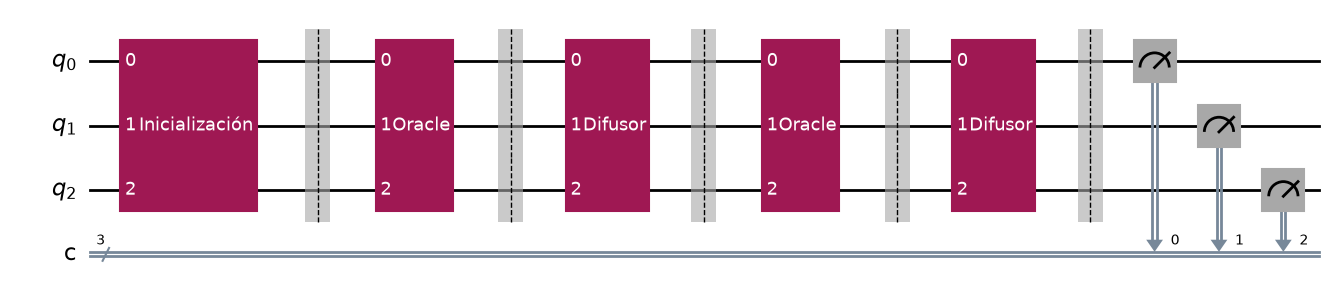

In [9]:
# Número de qubits
n = 3

# Estado objetivo (MSB → LSB), el mismo del tutorial
MarkState = '111'

k = Iteraciones(n)
print('Número de iteraciones k =', k)

grover_circuit = Grover(n, MarkState)
grover_circuit.draw('mpl')

In [10]:
state = Statevector(Grover(n, MarkState, medir=False))
print(state)
print('Probabilidad teórica de éxito P(' + MarkState + ') =', round(state.probabilities()[int(MarkState, 2)], 4))
state.draw('latex')

Statevector([-0.08838835+0.j, -0.08838835+0.j, -0.08838835+0.j,
             -0.08838835+0.j, -0.08838835+0.j, -0.08838835+0.j,
             -0.08838835+0.j,  0.97227182+0.j],
            dims=(2, 2, 2))
Probabilidad teórica de éxito P(111) = 0.9453


<IPython.core.display.Latex object>

{'010': 6, '000': 8, '111': 971, '011': 8, '101': 9, '110': 6, '100': 6, '001': 10}
Probabilidad de éxito medida P(111) = 0.9482421875


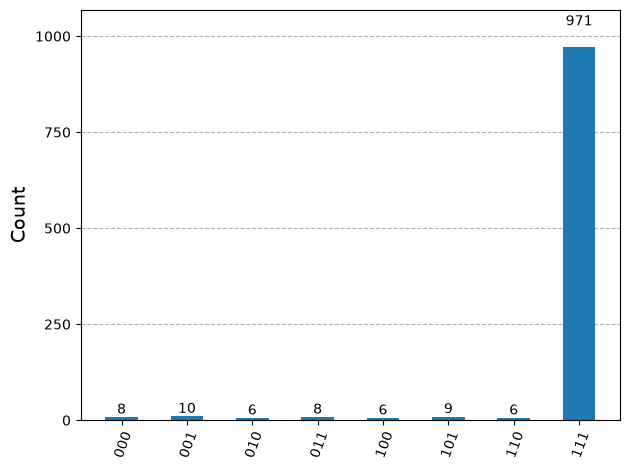

In [11]:
backend = AerSimulator(seed_simulator=2026)   # semilla fija para poder repetir el resultado
counts = backend.run(transpile(grover_circuit, backend), shots=1024).result().get_counts()
print(counts)
print('Probabilidad de éxito medida P(' + MarkState + ') =', counts.get(MarkState, 0) / 1024)
plot_histogram(counts)

## Comparación con el tutorial original de IBM Quantum

En la sección 4 del tutorial se busca $\lvert 111\rangle$ con 3 qubits de datos **más un qubit auxiliar**, y el número de iteraciones se escribe a mano
(`num_iterations = 2`, luego 3 y 4). Los conteos publicados en el tutorial (1024 disparos) son:

| Iteraciones | Conteos del tutorial |
|---|---|
| 2 | `{'0111': 977, '0100': 11, '0001': 8, '0000': 8, '0011': 5, '0010': 12, '0110': 3}` |
| 3 | `{'0010': 88, '0001': 103, '0000': 94, '0111': 334, '0100': 112, '0110': 106, '0101': 99, '0011': 88}` |
| 4 | `{'0110': 127, '0000': 135, '0001': 150, '0101': 164, '0010': 153, '0011': 131, '0100': 150, '0111': 14}` |

En las cadenas del tutorial el dígito de la izquierda es el auxiliar (vuelve a 0), así que `'0111'` es $\lvert 111\rangle$. Aquí no hay auxiliar
y el resultado es directamente `'111'`. Los conteos del tutorial vienen de otra ejecución con otra semilla, así que solo se pueden comparar
dentro de la variación estadística de 1024 disparos.

La celda siguiente repite las tres corridas del tutorial con el circuito modular.

 k   Teórica  Statevector  Este notebook  Tutorial
 2    0.9453       0.9453         0.9482    0.9541


 3    0.3301       0.3301         0.3145    0.3262


 4    0.0122       0.0122         0.0127    0.0137


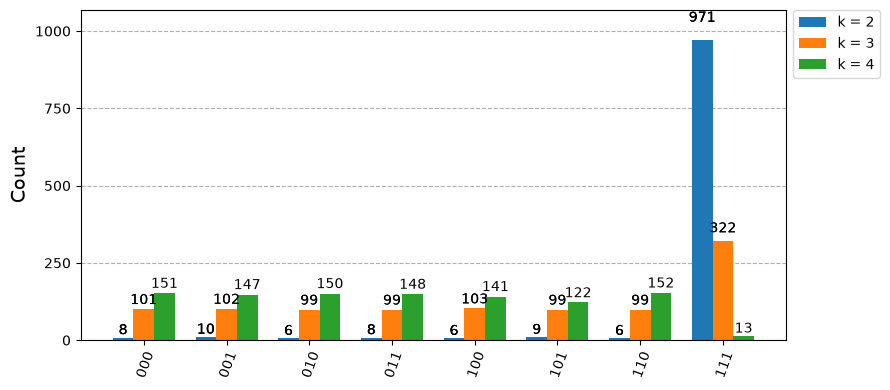

In [12]:
conteos_tutorial = {2: 977, 3: 334, 4: 14}       # conteos de '0111' publicados en el tutorial
theta = np.arcsin(1 / np.sqrt(2**n))

print(f"{'k':>2} {'Teórica':>9} {'Statevector':>12} {'Este notebook':>14} {'Tutorial':>9}")
resultados = {}
for k_i in [2, 3, 4]:
    p_teo = np.sin((2 * k_i + 1) * theta)**2
    p_sv = Statevector(Grover(n, MarkState, k_i, medir=False)).probabilities()[int(MarkState, 2)]
    c = backend.run(transpile(Grover(n, MarkState, k_i), backend), shots=1024).result().get_counts()
    resultados[f'k = {k_i}'] = c
    print(f"{k_i:>2} {p_teo:>9.4f} {p_sv:>12.4f} {c.get(MarkState, 0) / 1024:>14.4f} {conteos_tutorial[k_i] / 1024:>9.4f}")

plot_histogram(list(resultados.values()), legend=list(resultados.keys()), figsize=(9, 4))

## Varios estados marcados

`Iteraciones` usa $M$, el número de estados marcados. Con $n = 3$ y dos estados marcados, $\sin\theta = \sqrt{2/8} = 1/2$ ($\theta = 30^\circ$):
$k = \lfloor\frac{\pi}{4}\sqrt{4}\rfloor = 1$ y $(2k+1)\theta = 90^\circ$. La probabilidad de éxito es la **suma** de las probabilidades de los estados marcados y debe ser 1.

In [13]:
marcados = ['011', '110']
k2 = Iteraciones(3, len(marcados))
probs = Statevector(Grover(3, marcados, medir=False)).probabilities()
c2 = backend.run(transpile(Grover(3, marcados), backend), shots=1024).result().get_counts()

print('Estados marcados:', marcados, '  M =', len(marcados), '  k =', k2)
print('Probabilidad de éxito (suma, Statevector):', round(sum(probs[int(w, 2)] for w in marcados), 4))
print('Probabilidad de éxito (suma, medida)     :', sum(c2.get(w, 0) for w in marcados) / 1024)
print(c2)

Estados marcados: ['011', '110']   M = 2   k = 1
Probabilidad de éxito (suma, Statevector): 1.0
Probabilidad de éxito (suma, medida)     : 1.0
{'011': 524, '110': 500}


## Conclusiones

- `Iteraciones(3)` da $k = \lfloor 2.221 \rfloor = 2$, el mismo valor que el tutorial eligió a mano y que el propio tutorial señala como óptimo.
- Con $k=2$ la probabilidad teórica de éxito es $\sin^2(5\theta) = 0.9453$. El tutorial midió $977/1024 \approx 0.954$ y este notebook mide un valor
  parecido; la diferencia es variación estadística del muestreo con 1024 disparos.
- Con 3 y 4 iteraciones la probabilidad baja ($\approx 0.33$ y $\approx 0.01$), igual en el tutorial y aquí: más iteraciones no siempre es mejor,
  por eso conviene calcular $k$ automáticamente.
- A diferencia del tutorial, el circuito modular no usa qubit auxiliar ni limpieza, sirve para cualquier estado y para varios estados marcados.
- La probabilidad no llega a 1 con un estado marcado y $N=8$ porque $(2k+1)\theta$ no cae exactamente en $90^\circ$ ($5\theta \approx 103.5^\circ$).
  Con dos estados marcados sí cae justo en $90^\circ$ y la probabilidad es 1.

In [14]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Python Version:', python_version())
print('UdeA-Medellin (2026) ©')

Qiskit Version: 2.5.2
Qiskit_Aer Version: 0.18.2
Python Version: 3.13.14
UdeA-Medellin (2026) ©
